```latex
% 
\paragraph{Point-wise metadata assessment.} 
% 
We first derive and assess the individual characteristics of generated metadata instances:

\begin{enumerate}
    \item \emph{Structural Characteristics}: we derive the structural properties of the generated metadata instances as a synopses of their XML trees. We collect the tree sizes, depths, and node degrees.

    \item \emph{Syntactic Correctness}: we use the original XML Schema Definitions (XSD)s specified in the experiment set $\mathcal{S}$, to instantiate XML validators: $\mathcal{E}_{\dwctext}$ and $\mathcal{E}_{\eml}$. A validator receives a metadata instance, and returns a list of schema violations: $\mathcal{E}_{s\in\mathcal{S}}:\mathcal{M}\rightarrow[E_{s\in\mathcal{S}}]$.
    We apply it to metadata files created by \emph{massi} and store the pass or fail responses and all reported errors. We compute the correctness coefficient as: 
    \[
    corr(t_1,s) = 1 - \frac{\mid{\mathcal{E}_{s}(t_1)}\mid}{size(t_1)}
    \]
\end{enumerate}
```

and 

```latex
\paragraph{Pair-wise metadata assessment.}
% 
We assess same-schema metadata pairs: (1) generated and ground truth, and (2) generated by $\datafocus$ and $\authorfocus$.

\begin{enumerate}
    \item \emph{Structural Metadata Similarity}: we compute tree edit distance using the APTED algorithm~\cite{todo-apted-tree-edit-distance} to compare the structure of metadata instance pairs: generated-to-ground-truth, and generated-to-generated. To focus exclusively on the structure of the XML files, we replace all attribute and text node values with a placeholder: \texttt{hidden\_value}. We then report the normalized similarity score as: 
    \[
    % $
    sim(t_1, t_2) = 1 - \frac{APTED(t_1,t_2)}{size(t_1)+size(t_2)}
    % $.
    \]

    \item \emph{Common Metadata Patterns}: we detect the list of common embedded unique root-to-child paths, as frequent common sub-sequences, using the BIDE algorithm~\cite{todo-cite-bide}. For two XML trees $t_1$ and $t_2$, we extract a set of unique paths $paths(t)$, and compute common patterns with optional gaps, such that can be traversed in both XML documents. We report the degree of these shared patterns as: 
    \[
    % $
    pat(t_1, t_2) = 1 - \frac{BIDE(t_1,t_2)}{\mid{paths(t_1)}\mid + \mid{paths(t_2)}\mid}
    % $.
    \]

    \item \emph{Semantic Metadata Path Value Alignment}: for all shared patterns computed by BIDE, $P=BIDE(t_1,t_2)$, we also compute a semantic similarity score. We convert the common sequences into Xpath queries to retrieve the associated values $X^{p\in P}_{t_i}$ and calculate the semantic similarity scores: BERT cosine similarity, ROUGE-L, and BLEU, for a multi-perspective semantic assessment~\cite{todo-semantic-similarity-score-with-multiple-techniques}: $sem(p, t_1,t_2)$, computed as a weighted sum of the scores, where weights are $(0.5, 0.3,0.2)$ for values longer than 4 words and $(1,0,0)$ otherwise. We report the composite score: 
    \[
    % $
    val(t_1,t_2) = \frac{\sum_{p\in P}{sem(p, t_1,t_2)}}{\mid{P}\mid}
    % $
    \]

    \item \emph{Semantic Metadata Tree Alignment}: in addition to the granular semantic comparison of common embedded paths, we perform semantic comparison between the XML trees. We condense the XML data into bracket-tree notation: $bracket(t_i)$ and compute the cosine similarity score using CodeBERT model~\cite{todo-codebert-feng-et-al}. We then report the overall similarity score as: 
    \[
    % $
    glob(t_1,t_2)=CosSim_{CodeBERT}(bracket(t_1), bracket(t_2))
    % $.  
    \]
\end{enumerate}
```

so

```latex
\noindent
We define the composite generated metadata `alignment' score $Q$ for each tree metadata XML $t_1$, its ground truth or generated counterpart $t_2$, and schema $s$:
% 
\begin{align*}    
    &Align(t_1,t_2,s)=\vec{s} \cdot\vec{w},
    \\
    &\quad \text{with } \vec{s}=({corr(t_1,s), sim(t_1,t_2), pat(t_1,t_2), val(t_1,t_2), glob(t_1,t_2)})
    \\
    &\quad  \text{and } \vec{w}=({0.2, 0.3, 0.1, 0.2, 0.2})
\end{align*}
```

# Point-Wise Generated Metadata  

- Compute the following sub-section goals, grouped by `schema` and `strategy`. 

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
    Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
  Using cached setuptools-82.0.1-py3-none-any.whl (1.0 MB)
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file 'massi.egg-info/S

> **Collecting results and ground-truth cases**

In [324]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

In [325]:
gbif_cases = pd.read_csv("../../runtime/full_gbif_cases.csv")

In [326]:
experiment_results = pd.read_csv("../../runtime/experiment_cross_scenarios_cases.log.csv")

In [327]:
dwc_data_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "data-focus")]
dwc_author_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "author-focus")]

eml_data_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "data-focus")]
eml_author_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "author-focus")]

In [328]:
from IPython.display import display, display_markdown

> **Grouping by schema and strategy**

In [329]:
result_groups = {
    "DwC-x-Data": dwc_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
    "DwC-x-Author": dwc_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML-x-Data": eml_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML-x-Author": eml_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
}

for g, rs in result_groups.items():
    display(f"> --- Result Group: `{g}` ---")
    display(rs.describe())

'> --- Result Group: `DwC-x-Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,164.296089,0.0,0.0,153.513966,2.0,89.000000,46.359027,1.778160e+09
std,99.617169,0.0,0.0,99.156009,0.0,51.816986,77.392903,1.187505e+04
min,0.000000,0.0,0.0,0.000000,2.0,0.000000,12.870421,1.778149e+09
25%,84.500000,0.0,0.0,68.000000,2.0,44.500000,22.477583,1.778155e+09
50%,159.000000,0.0,0.0,151.000000,2.0,89.000000,30.010789,1.778159e+09
75%,263.500000,0.0,0.0,233.500000,2.0,133.500000,43.288641,1.778165e+09
max,444.000000,0.0,0.0,336.000000,2.0,178.000000,765.560462,1.778260e+09


'> --- Result Group: `DwC-x-Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,194.670391,4.0,4.0,153.513966,2.0,89.000000,42.249969,1.778161e+09
std,109.385350,0.0,0.0,99.156009,0.0,51.816986,54.813842,1.193789e+04
min,10.000000,4.0,4.0,0.000000,2.0,0.000000,14.248861,1.778150e+09
25%,114.500000,4.0,4.0,68.000000,2.0,44.500000,24.495313,1.778156e+09
50%,189.000000,4.0,4.0,151.000000,2.0,89.000000,29.604584,1.778160e+09
75%,310.500000,4.0,4.0,233.500000,2.0,133.500000,42.310426,1.778167e+09
max,445.000000,4.0,4.0,336.000000,2.0,178.000000,478.510206,1.778260e+09


'> --- Result Group: `EML-x-Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,515.670391,8.0,8.0,153.513966,2.0,89.000000,445.775805,1.778304e+09
std,97.111935,0.0,0.0,99.156009,0.0,51.816986,394.417847,3.889963e+04
min,354.000000,8.0,8.0,0.000000,2.0,0.000000,38.520714,1.778230e+09
25%,439.500000,8.0,8.0,68.000000,2.0,44.500000,312.525535,1.778249e+09
50%,527.000000,8.0,8.0,151.000000,2.0,89.000000,407.317098,1.778325e+09
75%,611.500000,8.0,8.0,233.500000,2.0,133.500000,496.024076,1.778331e+09
max,702.000000,8.0,8.0,336.000000,2.0,178.000000,4997.299114,1.778334e+09


'> --- Result Group: `EML-x-Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,555.363128,12.0,12.0,153.513966,2.0,89.000000,261.103811,1.778308e+09
std,108.616256,0.0,0.0,99.156009,0.0,51.816986,67.038688,3.772579e+04
min,356.000000,12.0,12.0,0.000000,2.0,0.000000,51.728838,1.778231e+09
25%,480.500000,12.0,12.0,68.000000,2.0,44.500000,221.043937,1.778322e+09
50%,567.000000,12.0,12.0,151.000000,2.0,89.000000,264.250012,1.778327e+09
75%,666.500000,12.0,12.0,233.500000,2.0,133.500000,305.515517,1.778333e+09
max,715.000000,12.0,12.0,336.000000,2.0,178.000000,466.105851,1.778335e+09


> **Some useful utilities**

In [330]:
import itertools as itlx

In [331]:
import tol_colors as tcls

In [332]:
from pathlib import Path

In [333]:
EXPERIMENT_BASE_DIR = "../../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [334]:
def ok_results(df):
    return df[df["success"]]

In [335]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/home/jovyan/.config/matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

In [336]:
mpl.rc('xtick', labelsize=6)
mpl.rc('ytick', labelsize=6)
plt.rcParams['axes.titlesize'] = 8

In [337]:
# Reusable subplot builder
def column_subplots(fig, subplot_source, data):
    for i, (l, lps, vsx, props, opts) in enumerate(data):
        ax = fig.add_subplot(subplot_source[i])
        ax.tick_params(axis="x", bottom=True, top=False)
        if (xscale := opts.get("xscale", "")):
            ax.set_xscale(xscale)
        if opts.get("boxplots", False):
            ax.boxplot(
                [vs for t, vs in vsx],
                tick_labels=[t for t, vs in vsx],
                flierprops=dict(markersize=2),
                zorder=10,
                **props
            )
            ax.set_xlabel(xl, fontsize=4) if (xl:=opts.get("xlabel", "")) else ...
            ax.set_ylabel(yl, fontsize=4) if (yl:=opts.get("ylabel", "")) else ...
        else:
            for t, vs in vsx:
                ax.hist(vs, **props, label=t, zorder=10)
                ax.set_xlabel(t, fontsize=4) if t else ...
        if (vlines := opts.get("vlines", [])):
            tway = ax.twiny()
            tway.set_xlim(ax.get_xlim())
            if (xscale := opts.get("xscale", "")):
                tway.set_xscale(xscale)
            for vl, vl_props in vlines:
                ax.axvline(
                    vl,
                    zorder=0,
                    **vl_props,
                )
            tway.set_xticks([vl for vl, _ in vlines])
            tway.set_xticklabels([vlp["label"] for _, vlp in vlines], fontsize=4, color="gray", rotation=90, fontstyle="italic")
            tway.tick_params(axis="x", color="gray", pad=1, length=1.75, labelfontfamily="serif")
            tway.minorticks_off()
        if (hists := opts.get("hists", [])):
            twax = ax.twinx()
            twax.set_xlim(ax.get_xlim())
            if (xscale := opts.get("xscale", "")):
                twax.set_xscale(xscale)
            for ht, ht_props in hists:
                twax.hist(
                    ht,
                    zorder=0,
                    **ht_props,
                )
            twax.set_yticks([],[])
        if opts.get("legend", False):
            ax.legend(fontsize=4)
        if opts.get("grid", False):
            ax.grid(alpha=0.25, ls=opts.get("gridls", "-"))
            ax.set_axisbelow(True)
        ax.set_title(l, size=8, **lps)

> **Now we are ready to proceed with the evaluations**

In [338]:
# see next cells

## [x] Structural Characteristics

- Nr successful trees
- XML tree size
- XML tree depths
- XML tree node degrees

### XML Tree Size

In [339]:
from typing import TypedDict, List, Dict, Any
from lxml import etree

class XMLTreeCharacteristics(TypedDict):
    size: int                         # Total number of elements/nodes
    node_depths: list[int]            # List of element path to its depth (0-indexed for root)
    node_degrees: list[int]           # List of element tag to its number of children
    num_text_nodes: int               # Count of non-empty text nodes
    num_attributes: int               # Total count of attributes across all nodes
    root_leaf_paths: list[list[str]]  # List of all root-to-leaf full paths
    root_leaf_xpaths: list[list[str]]  # List of all root-to-leaf XPath expressions
    num_root_leaf_paths: int          # Total number of unique root-to-leaf paths

In [340]:
from warnings import warn

class OutcomeContainer[T](TypedDict):
    value: T | None
    error: str | None

def do_or_error(func) -> OutcomeContainer[Any]: 
    def wrapper(*args, **kwargs):
        try:
            return {"value": func(*args, **kwargs), "error": None}
        except Exception as e:
            return {"error": f"{type(e)}: {str(e)}", "value": None}
    return wrapper

def do_on_value(func):
    def wrapper(c: OutcomeContainer[Any], *args, **kwargs):
        if c["value"] is not None:
            return func(c["value"], *args, **kwargs)
        else:
            return c
    return wrapper

In [432]:
@do_on_value
@do_or_error
def evaluate_xml_structure(tree):
    if hasattr(tree, "getroot"):
        return _evaluate_xml_structure(tree.getroot())
    return _evaluate_xml_structure(tree)


def _evaluate_xml_structure(root: etree._Element) -> XMLTreeCharacteristics:
    """
    Evaluates the structural characteristics of an lxml-parsed XML tree.
    """
    tree = etree.ElementTree(root)
    all_elements = list(root.iter())

    node_tags = [node.tag for node in all_elements]
    node_depths = [sum(1 for _ in node.iterancestors()) for node in all_elements]
    node_degrees = [len(node) for node in all_elements]
    
    size = len(all_elements)
    num_text_nodes = sum(1 for el in all_elements if el.text and el.text.strip())
    num_attributes = sum(len(el.attrib) for el in all_elements)
    leaf_elements = [el for el in all_elements if len(el) == 0 and isinstance(el.tag, str)]
    root_leaf_paths = [tree.getelementpath(el) for el in leaf_elements]
    root_leaf_xpaths = [tree.getpath(el) for el in leaf_elements]
    num_root_leaf_paths = len(root_leaf_paths)
    
    return {
        "size": size,
        "all_nodes": node_tags,
        "node_depths": node_depths,
        "node_degrees": node_degrees,
        "num_text_nodes": num_text_nodes,
        "num_attributes": num_attributes,
        "root_leaf_paths": root_leaf_paths,
        "root_leaf_xpaths": root_leaf_xpaths,
        "num_root_leaf_paths": num_root_leaf_paths
    }

In [342]:
@do_or_error
def parse_xml_file(path: str | Path):
    return etree.parse(path)

@do_or_error
def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

In [343]:
import re 

@do_on_value
@do_or_error
def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

@do_on_value
@do_or_error
def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [344]:
import json

In [345]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_dict"] = rs["outcome_json"].apply(json.loads)

In [346]:
@do_or_error
def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml"] = rs["outcome_dict"].apply(resolve_xml_content)

In [347]:
@do_on_value
def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml.clean"] = rs["outcome_metadata_xml"].apply(cleanup_gap_failures).apply(cleanup_special_characters)
    result_groups[g]["xml_tree"] = result_groups[g]["outcome_metadata_xml.clean"].apply(parse_xml_content)

In [433]:
for g, rs in result_groups.items():
    result_groups[g]["xml_tree.characteristics"] = rs["xml_tree"].apply(evaluate_xml_structure)

In [349]:
def with_ok_parsed_trees(df):
    return df[df["xml_tree"].apply(lambda x: x["value"] is not None)]

In [350]:
for g, rs in result_groups.items():
    print(f"--- {g} ---")
    print(result_groups[g].shape[0])
    print(with_ok_parsed_trees(result_groups[g]).shape[0])
    print(ok_results(result_groups[g]).shape[0])

--- DwC-x-Data ---
179
174
179
--- DwC-x-Author ---
179
174
175
--- EML-x-Data ---
179
150
155
--- EML-x-Author ---
179
148
158


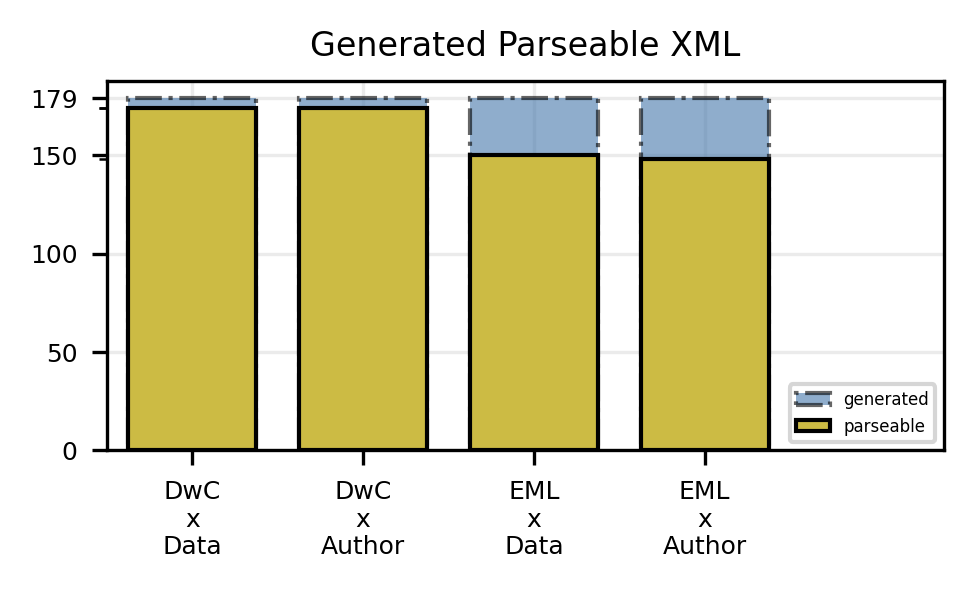

In [351]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3.6, 1.6))

experiment_groups = np.array(["\n".join(g.split("-")) for g, rs in result_groups.items()])
experiment_count = np.array([rs.shape[0] for g, rs in result_groups.items()])
ok_experiment_count = np.array([with_ok_parsed_trees(rs).shape[0] for g, rs in result_groups.items()])

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="-.", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

plt.savefig("generated-parseable-xml-count.pdf")
plt.savefig("generated-parseable-xml-count.png")
plt.show()

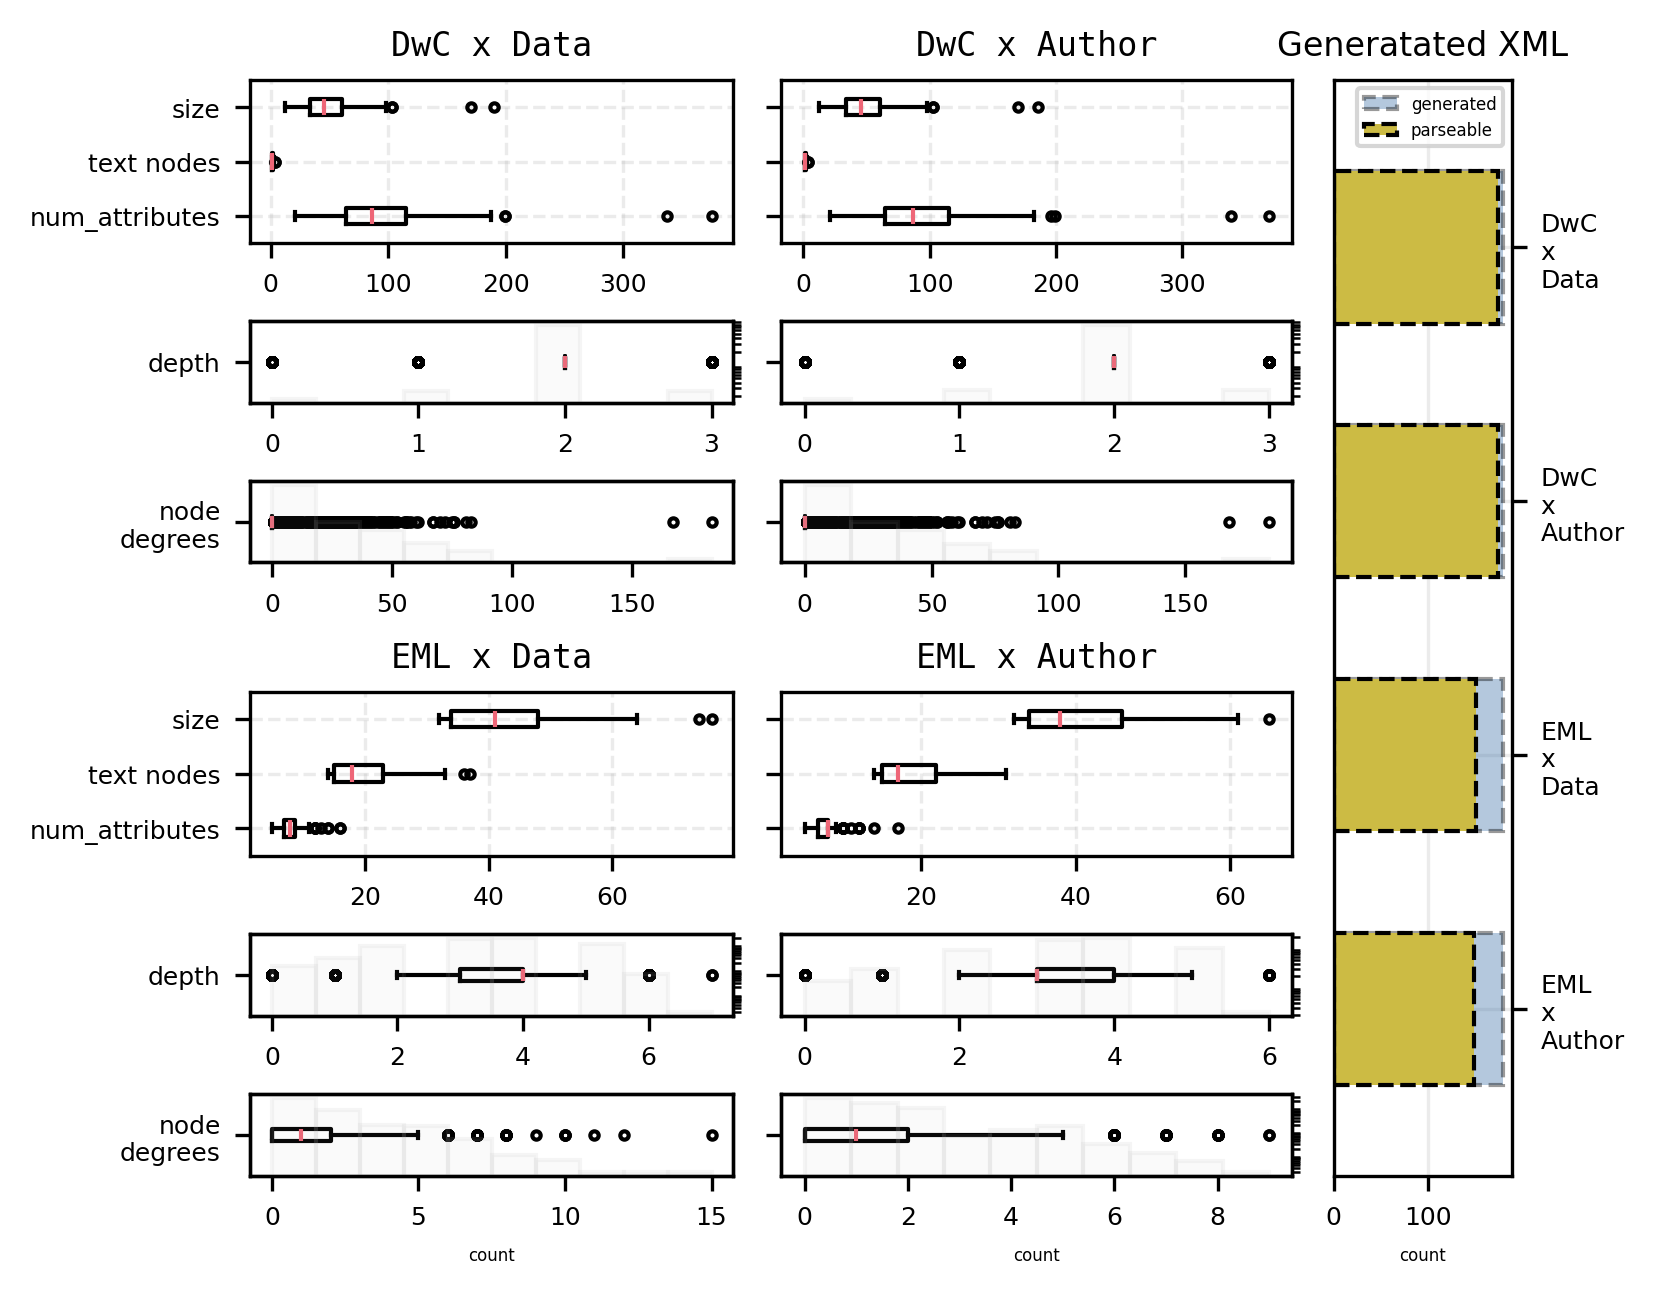

In [352]:
figsize = (5.4, 4.2)
dpi = 300
layout = """
    AAAABBBE
    CCCCDDDE
"""

fig, axd = plt.subplot_mosaic(
    layout,
    figsize=figsize,
    dpi=dpi,
    constrained_layout=True
)

axd["E"].set_title("Generatated XML", size=8)
axd["E"].barh(
    list(reversed(experiment_groups)), 
    list(reversed(experiment_count)),
    height=0.6, 
    label="generated",
    color=tcls.bright[0], 
    alpha=0.4,
    edgecolor="black", 
    ls="--",
)
axd["E"].barh(
    list(reversed(experiment_groups)), 
    list(reversed(ok_experiment_count)), 
    height=0.6,
    label="parseable",
    color=tcls.bright[3],
    # alpha=0.8,
    edgecolor="black",
    ls="--"
)
# axd["E"].set_xticks(ok_experiment_count, minor=True)
axd["E"].set_ymargin(0.1)
axd["E"].set_xlabel("count", fontsize=4)
axd["E"].yaxis.set_label_position("right")
axd["E"].yaxis.tick_right()
axd["E"].legend(fontsize=4, loc="upper right")
axd["E"].grid(alpha=0.25)
axd["E"].set_axisbelow(True)


axs = [axd["A"],axd["B"],axd["C"],axd["D"]] 
axs_x_groups = zip(axs, result_groups.keys())

for i, (ax, g) in enumerate(axs_x_groups):
    # ax.set_title(g.replace("-", " "))
    gs_ax_g = ax.get_subplotspec().subgridspec(3, 1, height_ratios=[2,1,1])
    ok_cases = with_ok_parsed_trees(result_groups[g])

    odd = not (i % 2)
    bottom = i > 1
    
    column_subplots(
        fig, 
        gs_ax_g, 
        [
            (
                g.replace("-", " "), dict(fontfamily="monospace"),
                [
                    ("num_attributes" if odd else "", ok_cases["xml_tree.characteristics"].apply(lambda d: d["value"]["num_attributes"])),
                    ("text nodes" if odd else "", ok_cases["xml_tree.characteristics"].apply(lambda d: d["value"]["num_text_nodes"])),
                    ("size" if odd else "", ok_cases["xml_tree.characteristics"].apply(lambda d: d["value"]["size"])),
                ],
                dict(vert=False),
                dict(
                    grid=True,
                    gridls="--",
                    boxplots=True, 
                    # xscale="symlog", 
                )
            ),
            (
                "", 
                {},
                [("depth" if odd else "", depths)],
                dict(vert=False),
                dict(
                    boxplots=True, 
                    hists=[(depths, dict(log=True, ls="-", color="#aeaeae0d", edgecolor="#aeaeae1d", linewidth=1))]
                )
            ) if (depths := list(itlx.chain.from_iterable(ok_cases["xml_tree.characteristics"].apply(lambda d: d["value"]["node_depths"])))) else ...,
            (
                "", 
                {},
                [("node\ndegrees" if odd else "", degrees)],
                dict(vert=False),
                dict(
                    boxplots=True, 
                    xlabel="count" if bottom else "", 
                    # xscale="symlog", 
                    hists=[(degrees, dict(log=True, ls="-", color="#aeaeae0d", edgecolor="#aeaeae1d", linewidth=1))]
                )
            ) if (degrees := list(itlx.chain.from_iterable(ok_cases["xml_tree.characteristics"].apply(lambda d: d["value"]["node_degrees"])))) else ...,
        ],
    )
    ax.axis('off')

# plt.tight_layout()

plt.savefig("generated-parseable-xml-structural-overview.pdf")
plt.savefig("generated-parseable-xml-structural-overview.png")
plt.show()

## [x] Syntactic Correctness

- XML validity given the XSD schema validator

In [353]:
import functools as fctlx

In [354]:
import massi.agents.tools as matls

In [355]:
dwc_validator = matls.get_xmlschema_validator('http://rs.tdwg.org/dwc/text/tdwg_dwc_text.xsd')
eml_validator = matls.get_xmlschema_validator('https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd')

/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [356]:
result_group_schema_validators = {
    "DwC-x-Data": dwc_validator,
    "DwC-x-Author": dwc_validator, 
    "EML-x-Data": eml_validator, 
    "EML-x-Author": eml_validator,
}

@do_on_value
def validate_by_schema(xml_data, validator=None): 
    return validator.validate(xml_data)

In [357]:
for i, row in with_ok_parsed_trees(rs).iterrows():
    try:
        dwc_validator.validate(row["outcome_metadata_xml.clean"]["value"])
    except Exception as e:
        print(i)
        print(row["scenario_x_case_tag"])
        print(e)
        print(row["outcome_metadata_xml.clean"]["value"][:250])
        print(row["outcome_metadata_xml"]["value"][:250])        

In [358]:
for g, rs in result_groups.items():
    result_groups[g]["xml_schema_validation"] = with_ok_parsed_trees(rs)["outcome_metadata_xml.clean"].apply(lambda d: validate_by_schema(d, result_group_schema_validators[g]))
    result_groups[g]["xml_schema_validation.ok"] = result_groups[g]["xml_schema_validation"].apply(lambda x: x[0] if isinstance(x, tuple) else x)
    result_groups[g]["xml_schema_validation.errors"] = result_groups[g]["xml_schema_validation"].apply(lambda x: x[1] if isinstance(x, tuple) else x)
    result_groups[g]["xml_schema_validation.error_count"] = with_ok_parsed_trees(result_groups[g])["xml_schema_validation.errors"].apply(len)
    result_groups[g]["xml_schema_validation.ratio"] = with_ok_parsed_trees(result_groups[g])["xml_schema_validation.error_count"].div(
        with_ok_parsed_trees(result_groups[g])["xml_tree.characteristics"].apply(lambda c: c["value"]["size"]).tolist()
    )
    result_groups[g]["xml_schema_validation.percentage"] = with_ok_parsed_trees(result_groups[g])["xml_schema_validation.ratio"] * 100
    result_groups[g]["xml_schema_validation.correctness_metric"] = 1 - with_ok_parsed_trees(result_groups[g])["xml_schema_validation.ratio"]

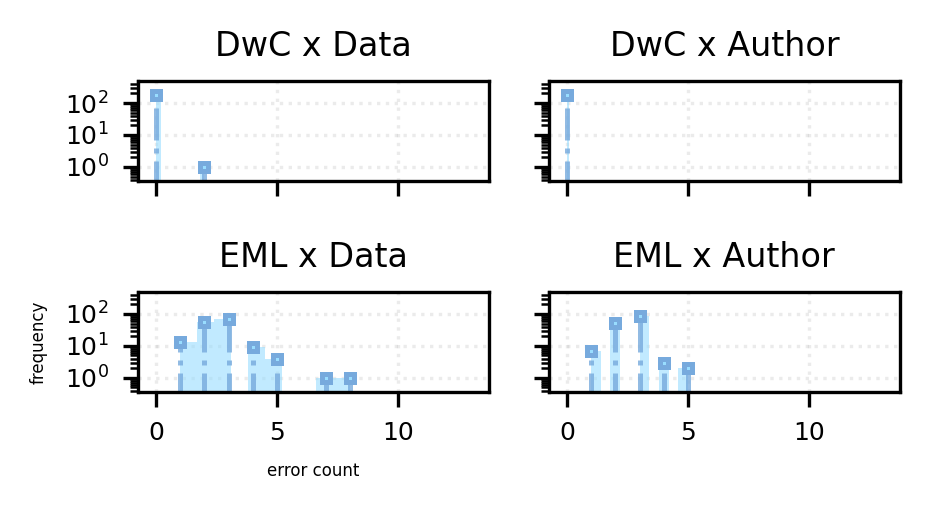

In [359]:
fig, axs = plt.subplots(2, 2, dpi=300, figsize=(3.2,1.8), sharex=True, sharey=True)

for i, (ax, (g, rs)) in enumerate(zip(itlx.chain.from_iterable(axs), result_groups.items())):
    ok_rs = with_ok_parsed_trees(rs)
    ax.set_title(g.replace("-", " "))
    ax.hist(ok_rs["xml_schema_validation.error_count"], color=tcls.light[4], log=True, alpha=0.6)
    ax.vlines(
        ymin=0, 
        ymax=ok_rs["xml_schema_validation.error_count"].value_counts().values, 
        x=ok_rs["xml_schema_validation.error_count"].value_counts().index, 
        ls="-.",
        color=tcls.light[0],
        linewidth=1.2,
        alpha=0.8
    )
    ax.plot(
        ok_rs["xml_schema_validation.error_count"].value_counts(), 
        marker="s", 
        color="#ffffff00", 
        markerfacecolor=tcls.light[4], 
        markeredgecolor=tcls.light[0], 
        markeredgewidth=1.2,
        markersize=2,
        label=""
    )
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)
    ax.set_xlim(-0.75,13.75)
    ax.set_ymargin(0.2)
    ax.set_xmargin(0.4)
    ax.set_ylabel("frequency", fontsize=4) if (i == 2) else ...
    ax.set_xlabel("error count", fontsize=4) if (i == 2) else ...

# fig.suptitle("XML Validation Errors", fontsize=8)

plt.tight_layout()
plt.savefig("generated-pareseable-xml-error-counts.pdf")
plt.savefig("generated-pareseable-xml-error-counts.png")
plt.show()

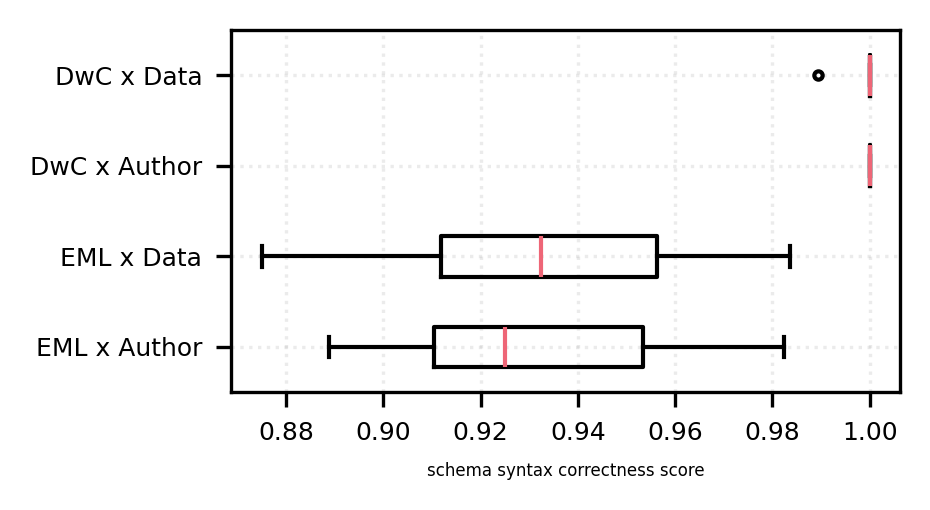

In [360]:
fig, ax = plt.subplots(1, 1, dpi=300, figsize=(3.2,1.8))

# ax.set_title("XML Schema Syntactic Correctness Score")
ax.boxplot(
    [
       with_ok_parsed_trees(rs)["xml_schema_validation.correctness_metric"]
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    tick_labels=[
       g.replace("-", " ")
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    vert=False,
    flierprops=dict(markersize=2),
)
ax.set_xlabel("schema syntax correctness score", fontsize=4)
ax.grid(alpha=0.25, ls=":")
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig("generated-pareseable-xml-schema-validation-score.pdf")
plt.savefig("generated-pareseable-xml-schema-validation-score.png")
plt.show()

# Pair-wise Metadata Assessment

> **Load the ground truth metadata**

In [361]:
result_group_2_ground_truth = {
    "DwC-x-Data": "ground_truth_metadata_dwc",
    "DwC-x-Author": "ground_truth_metadata_dwc", 
    "EML-x-Data": "ground_truth_metadata_eml", 
    "EML-x-Author": "ground_truth_metadata_eml",
}

In [362]:
cross_group_key_pairs = {
    ("DwC-x-Data", "DwC-x-Author"),
    ("EML-x-Data", "EML-x-Author"),
}

## [x] Structural Metadata Similarity

- similiarity as normalised `APTED` tree distance

In [363]:
import apted

In [364]:
@do_on_value
@do_or_error
def xml_to_apted_tree(tree):
    if hasattr(tree, "getroot"):
        return convert_xml_to_apted(tree.getroot())
    return convert_xml_to_apted(tree)

def convert_xml_to_apted(root):
    tag = root.tag
    
    if root.attrib:
        attr_parts = [f"{{key__{k}:{{hidden_value}}}}" for k, _v in sorted(root.attrib.items())]
        node_label = f"{tag}:{':'.join(attr_parts)}"
    else:
        node_label = tag
    
    apted_children = [convert_xml_to_apted(child) for child in root]    
    return apted.helpers.Tree(node_label, *apted_children)

In [365]:
def apted_tree_size(tree):
    return 1 + sum(apted_tree_size(child) for child in tree.children)

In [366]:
def normalise_distance(raw_distance, tree1, tree2):
    max_dist = apted_tree_size(tree1) + apted_tree_size(tree2)
    return raw_distance / max_dist if max_dist > 0 else 0

In [367]:
def get_error_breakdown(apted_edit_mapping):
    breakdown = {
        "deletions": [],    # In Tree 1, but not in Tree 2
        "insertions": [],   # In Tree 2, but not in Tree 1
        "renames": [],      # In both, but labels/attributes differ
        "matches": []       # Identical nodes
    }
    
    for node1, node2 in apted_edit_mapping:
        if node1 is None:
            # Node exists only in generated (Tree 2) -> Hallucination
            breakdown["insertions"].append(node2.name)
        elif node2 is None:
            # Node exists only in ground truth (Tree 1) -> Omission
            breakdown["deletions"].append(node1.name)
        else:
            # Both exist; check if the label (tag + attributes) is the same
            if node1.name != node2.name:
                breakdown["renames"].append((node1.name, node2.name))
            else:
                breakdown["matches"].append(node1.name)
                
    return breakdown

In [368]:
for g, rs in result_groups.items():
    result_groups[g]["apted_tree"] = with_ok_parsed_trees(rs)["xml_tree"].apply(xml_to_apted_tree)

In [369]:
result_groups[g]["apted_tree"][0]

{'value': {{https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}{dataset{title}{creator{individualName{surName}}{userId:{key__directory:{hidden_value}}}}{abstract{para}}{methods{methodStep{description{para}}{instrumentation}}{methodStep{description{para}}}{qualityControl{description{para}}}}{project{title}{personnel{individualName{surName}}{role}}{personnel{individualName{surName}}{role}}{personnel{individualName{surName}}{role}}{funding{para}}{studyAreaDescription{descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}{descriptorValue}}{descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}{descriptorValue}}}}{maintenance{description{para}}{maintenanceUpdateFrequency}}}{additionalMetadata{metadata}}}, 'error': None}

In [370]:
for g, rs in result_groups.items():
    gt_key = result_group_2_ground_truth[g]
    result_groups[g]["ground_truth_xml_tree"] = with_ok_parsed_trees(rs)[gt_key].apply(grounded_path).apply(parse_xml_file)
    result_groups[g]["ground_truth_apted_tree"] = with_ok_parsed_trees(rs)["ground_truth_xml_tree"].apply(xml_to_apted_tree)

In [371]:
result_groups[g]["ground_truth_apted_tree"][0]

{'value': {{https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__scope:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/2001/XMLSchema-instance}schemaLocation:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}{dataset{alternateIdentifier}{alternateIdentifier}{shortName}{title:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}}{creator{individualName{givenName}{surName}}{organizationName}{positionName}{address{deliveryPoint}{city}{administrativeArea}{postalCode}{country}}{phone}{electronicMailAddress}}{creator{individualName{givenName}{surName}}{organizationName}{positionName}{address{deliveryPoint}{city}{administrativeArea}{postalCode}{country}}{phone}{electronicMailAddress}{onlineUrl}{userId:{key__directory:{hidden_value}}}}{creator{individualName{givenName}{surName}}{organizationName}{positionName}{address{deliveryPoint}{city}{postalCode}{country}}{electronicMailAddress}}{creator{individual

In [372]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["tree_distance.apted.ground_truth"] = with_ok_parsed_trees(rs).apply(
        lambda x: apted.APTED(x["apted_tree"]["value"], x["ground_truth_apted_tree"]["value"]), 
        axis=1,
    ).apply(
        lambda a: dict(edit_distance=a.compute_edit_distance())
    )

CPU times: user 1min 7s, sys: 0 ns, total: 1min 7s
Wall time: 1min 6s


In [373]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["tree_distance.apted.edit_mapping"] = with_ok_parsed_trees(rs).apply(
        lambda x: apted.APTED(x["apted_tree"]["value"], x["ground_truth_apted_tree"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_mapping()
    )

CPU times: user 1min 13s, sys: 0 ns, total: 1min 13s
Wall time: 1min 11s


In [374]:
result_groups[g]["tree_distance.apted.edit_mapping"]

0      [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
1                                                    NaN
2      [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
3      [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
4      [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
                             ...                        
174    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
175                                                  NaN
176    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
177    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
178    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
Name: tree_distance.apted.edit_mapping, Length: 179, dtype: object

In [375]:
for g, rs in result_groups.items():
    result_groups[g]["tree_distance.apted.edit_mapping.breakdown"] = with_ok_parsed_trees(rs)["tree_distance.apted.edit_mapping"].apply(get_error_breakdown)

In [376]:
cross_group_pairs = {}

for g1, g2 in cross_group_key_pairs:
    cross_group_pairs[(g1,g2)] = with_ok_parsed_trees(result_groups[g1]).merge(
        with_ok_parsed_trees(result_groups[g2]), 
        on="case_id", 
        how="inner", 
        suffixes=["-g1", "-g2"]
    )

In [377]:
print(cross_group_pairs[(g1,g2)].columns.tolist())

['index-g1', 'Unnamed: 0_x-g1', 'variant-g1', 'schema-g1', 'strategy-g1', 'provider-g1', 'config-g1', 'scenario_id-g1', 'scenario_tag-g1', 'Unnamed: 0_y-g1', 'title-g1', 'authors-g1', 'source-g1', 'published-g1', 'open_access-g1', 'peer_review-g1', 'citation_type-g1', 'countries_of_coverage-g1', 'countries_of_researcher-g1', 'keywords-g1', 'literature_type-g1', 'websites-g1', 'identifiers-g1', 'id-g1', 'topics-g1', 'added-g1', 'gbif_download_key-g1', 'gbif_data_id_data-g1', 'dwca_url-g1', 'data_standard-g1', 'doi_url-g1', 'genre-g1', 'has_repository_copy-g1', 'is_oa-g1', 'journal_name-g1', 'published_date-g1', 'publisher-g1', 'best_oa_location.endpoint_id-g1', 'best_oa_location.oa_date-g1', 'best_oa_location.url-g1', 'best_oa_location.url_for_landing_page-g1', 'best_oa_location.url_for_pdf-g1', 'paper_download_file_path-g1', 'dwca_download_path-g1', 'dwca_zip_info-g1', 'paper_download_info-g1', 'working_copy_data_dir-g1', 'ground_truth_paper_path-g1', 'ground_truth_metadata_dir-g1', 'g

In [378]:
cross_group_pairs[(g1,g2)][["case_id", "strategy-g1", "strategy-g2"]]

,case_id,strategy-g1,strategy-g2
0,0,data-focus,author-focus
1,1,data-focus,author-focus
2,10,data-focus,author-focus
3,100,data-focus,author-focus
4,101,data-focus,author-focus
...,...,...,...
164,95,data-focus,author-focus
165,96,data-focus,author-focus
166,97,data-focus,author-focus
167,98,data-focus,author-focus


In [379]:
%%time
for (g1, g2), jrs in cross_group_pairs.items():
    cross_group_pairs[(g1, g2)]["tree_distance.apted.g1-g2"] = jrs.apply(
        lambda x: apted.APTED(x["apted_tree-g1"]["value"], x["apted_tree-g2"]["value"]), 
        axis=1,
    ).apply(
        lambda a: dict(edit_distance=a.compute_edit_distance())
    )

CPU times: user 6.4 s, sys: 0 ns, total: 6.4 s
Wall time: 6.29 s


In [380]:
result_groups[g]["tree_distance.apted.ground_truth"][0]

{'edit_distance': 479}

In [381]:
cross_group_pairs[(g1, g2)]["tree_distance.apted.g1-g2"]

0      {'edit_distance': 0}
1      {'edit_distance': 0}
2      {'edit_distance': 1}
3      {'edit_distance': 1}
4      {'edit_distance': 0}
               ...         
164    {'edit_distance': 1}
165    {'edit_distance': 0}
166    {'edit_distance': 1}
167    {'edit_distance': 4}
168    {'edit_distance': 0}
Name: tree_distance.apted.g1-g2, Length: 169, dtype: object

In [382]:
for g, rs in result_groups.items():
    result_groups[g]["tree_distance.apted.ground_truth.value"] = with_ok_parsed_trees(rs)["tree_distance.apted.ground_truth"].apply(
        lambda d: d["edit_distance"]
    )
    result_groups[g]["tree_distance.apted.ground_truth.normalised"] = with_ok_parsed_trees(rs).apply(
        lambda x: normalise_distance(x["tree_distance.apted.ground_truth.value"], x["apted_tree"]["value"], x["ground_truth_apted_tree"]["value"]), 
        axis=1
    )
    result_groups[g]["tree_distance.apted.ground_truth.similarity_score"] = 1 - with_ok_parsed_trees(rs)["tree_distance.apted.ground_truth.normalised"]

In [383]:
for (g1, g2), jrs in cross_group_pairs.items():
    cross_group_pairs[(g1, g2)]["tree_distance.apted.g1-g2.value"] = jrs["tree_distance.apted.g1-g2"].apply(
        lambda d: d["edit_distance"]
    )
    cross_group_pairs[(g1, g2)]["tree_distance.apted.g1-g2.normalised"] = jrs.apply(
        lambda x: normalise_distance(x["tree_distance.apted.g1-g2.value"], x["apted_tree-g1"]["value"], x["apted_tree-g2"]["value"]), 
        axis=1
    )
    cross_group_pairs[(g1, g2)]["tree_distance.apted.g1-g2.similarity_score"] = 1 - jrs["tree_distance.apted.g1-g2.normalised"]

> **Generated-to-Ground-Truth**

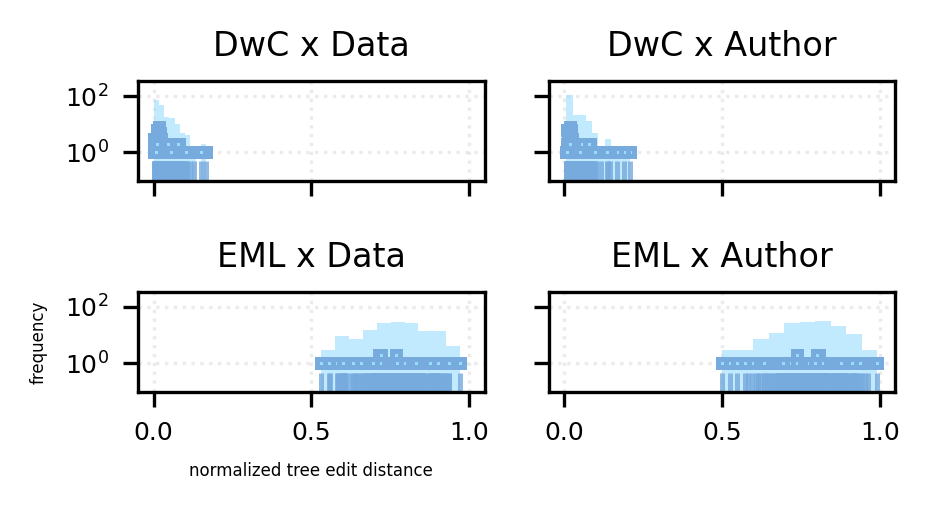

In [384]:
fig, axs = plt.subplots(2, 2, dpi=300, figsize=(3.2,1.8), sharex=True, sharey=True)

for i, (ax, (g, rs)) in enumerate(zip(itlx.chain.from_iterable(axs), result_groups.items())):
    ok_rs = with_ok_parsed_trees(rs)
    ax.set_title(g.replace("-", " "))
    ax.hist(ok_rs["tree_distance.apted.ground_truth.normalised"], color=tcls.light[4], log=True, alpha=0.6)
    ax.vlines(
        ymin=0, 
        ymax=ok_rs["tree_distance.apted.ground_truth.normalised"].value_counts().values, 
        x=ok_rs["tree_distance.apted.ground_truth.normalised"].value_counts().index, 
        ls="-.",
        color=tcls.light[0],
        linewidth=1.2,
        alpha=0.8
    )
    ax.plot(
        ok_rs["tree_distance.apted.ground_truth.normalised"].value_counts(), 
        marker="s", 
        color="#ffffff00", 
        markerfacecolor=tcls.light[4], 
        markeredgecolor=tcls.light[0], 
        markeredgewidth=1.2,
        markersize=2,
        label=""
    )
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ymargin(0.2)
    ax.set_xmargin(0.4)
    ax.set_ylabel("frequency", fontsize=4) if (i == 2) else ...
    ax.set_xlabel("normalized tree edit distance", fontsize=4) if (i == 2) else ...


plt.tight_layout()

plt.savefig("generated-pareseable-xml-gt-edit-distance-norm.pdf")
plt.savefig("generated-pareseable-xml-gt-edit-distance-norm.png")
plt.show()

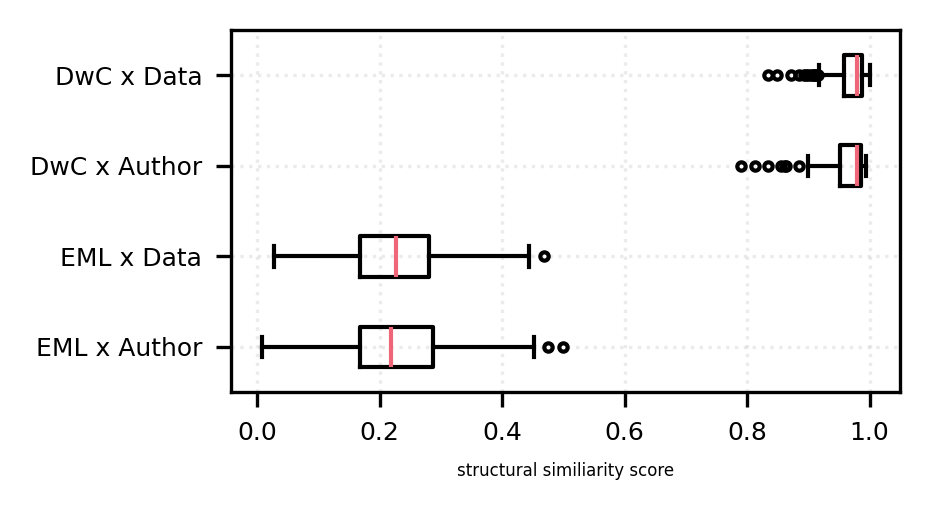

In [385]:
fig, ax = plt.subplots(1, 1, dpi=300, figsize=(3.2,1.8))

# ax.set_title("Ground Truth XML Structural Similiarity Score")
ax.boxplot(
    [
       with_ok_parsed_trees(rs)["tree_distance.apted.ground_truth.similarity_score"]
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    tick_labels=[
       g.replace("-", " ")
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    vert=False,
    flierprops=dict(markersize=2),
)
ax.set_xlabel("structural similiarity score", fontsize=4)
ax.grid(alpha=0.25, ls=":")
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig("generated-pareseable-xml-gt-edit-distance-sim-score.pdf")
plt.savefig("generated-pareseable-xml-gt-edit-distance-sim-score.png")
plt.show()

> **Generated-to-Generated**

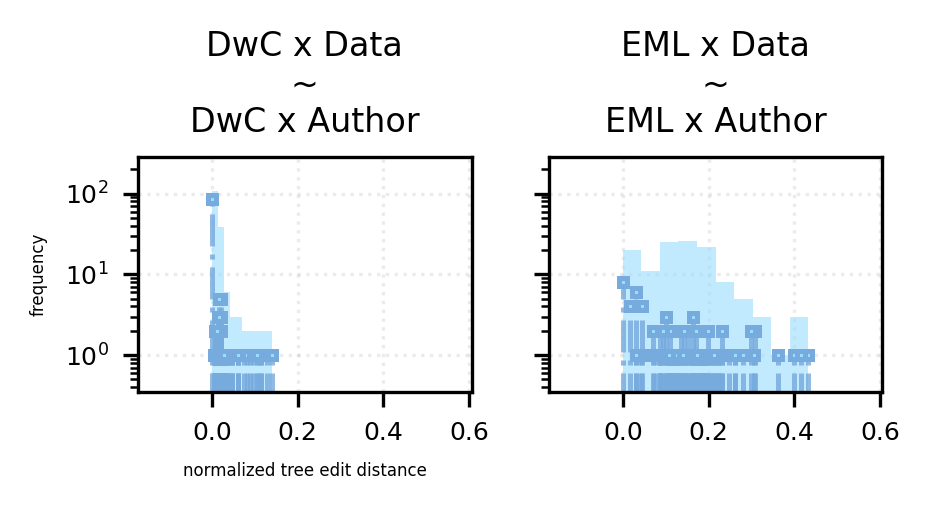

In [386]:
fig, axs = plt.subplots(1, 2, dpi=300, figsize=(3.2, 1.8), sharex=True, sharey=True)

for i, (ax, ((g1,g2), jrs)) in enumerate(zip(axs, reversed(list(cross_group_pairs.items())))):
    # print(jrs["tree_distance.apted.g1-g2.normalised"].describe())
    ax.set_title(f"{g1}\n~\n{g2}".replace("-", " "))
    ax.hist(jrs["tree_distance.apted.g1-g2.normalised"], color=tcls.light[4], log=True, alpha=0.6)
    ax.vlines(
        ymin=0, 
        ymax=jrs["tree_distance.apted.g1-g2.normalised"].value_counts().values, 
        x=jrs["tree_distance.apted.g1-g2.normalised"].value_counts().index, 
        ls="-.",
        color=tcls.light[0],
        linewidth=1.2,
        alpha=0.8
    )
    ax.plot(
        jrs["tree_distance.apted.g1-g2.normalised"].value_counts(), 
        marker="s", 
        color="#ffffff00", 
        markerfacecolor=tcls.light[4], 
        markeredgecolor=tcls.light[0], 
        markeredgewidth=1.2,
        markersize=2,
        label=""
    )
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)
    ax.set_ymargin(0.2)
    ax.set_xmargin(0.4)
    ax.set_ylabel("frequency", fontsize=4) if (i == 0) else ...
    ax.set_xlabel("normalized tree edit distance", fontsize=4) if (i == 0) else ...

# fig.suptitle("Cross-Strategy Generated XML Tree Edit Distance", fontsize=8)

plt.tight_layout()

plt.savefig("generated-pareseable-xml-gen-gen-edit-distance-norm.pdf")
plt.savefig("generated-pareseable-xml-gen-gen-edit-distance-norm.png")
plt.show()

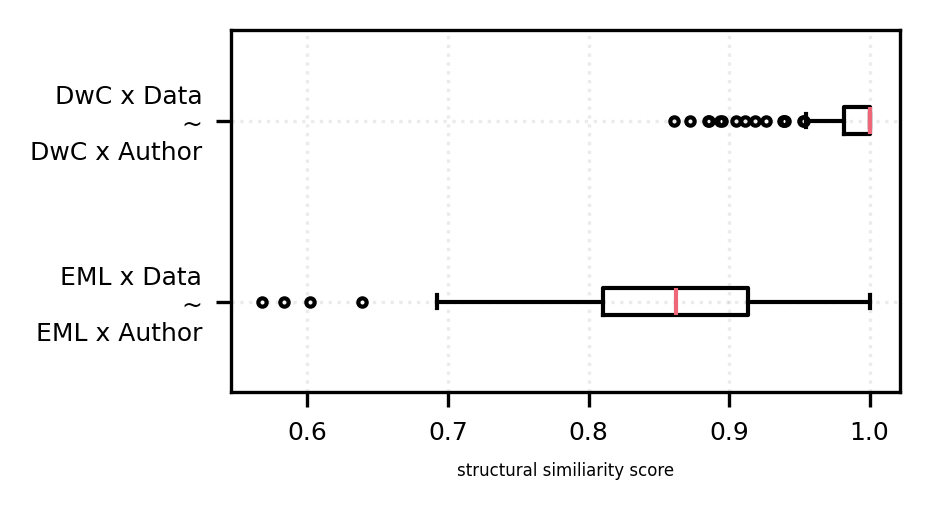

In [387]:
fig, ax = plt.subplots(1, 1, dpi=300, figsize=(3.2,1.8))



# ax.set_title("Generated XML Structural Similiarity Score")
ax.boxplot(
    [
       jrs["tree_distance.apted.g1-g2.similarity_score"]
       for (gs, jrs) in list(cross_group_pairs.items())
    ],
    tick_labels=[
       f"{g1}\n~\n{g2}".replace("-", " ")
       for ((g1,g2), rs) in list(cross_group_pairs.items())
    ],
    vert=False,
    flierprops=dict(markersize=2),
)
ax.set_xlabel("structural similiarity score", fontsize=4)
ax.grid(alpha=0.25, ls=":")
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig("generated-pareseable-xml-gen-gen-edit-distance-sim-score.pdf")
plt.savefig("generated-pareseable-xml-gen-gen-edit-distance-sim-score.png")
plt.show()

In [388]:
(g1,g2), jrs = list(cross_group_pairs.items())[0]

In [389]:
print(g1,g2)

EML-x-Data EML-x-Author


In [390]:
print(jrs.columns.tolist())

['index-g1', 'Unnamed: 0_x-g1', 'variant-g1', 'schema-g1', 'strategy-g1', 'provider-g1', 'config-g1', 'scenario_id-g1', 'scenario_tag-g1', 'Unnamed: 0_y-g1', 'title-g1', 'authors-g1', 'source-g1', 'published-g1', 'open_access-g1', 'peer_review-g1', 'citation_type-g1', 'countries_of_coverage-g1', 'countries_of_researcher-g1', 'keywords-g1', 'literature_type-g1', 'websites-g1', 'identifiers-g1', 'id-g1', 'topics-g1', 'added-g1', 'gbif_download_key-g1', 'gbif_data_id_data-g1', 'dwca_url-g1', 'data_standard-g1', 'doi_url-g1', 'genre-g1', 'has_repository_copy-g1', 'is_oa-g1', 'journal_name-g1', 'published_date-g1', 'publisher-g1', 'best_oa_location.endpoint_id-g1', 'best_oa_location.oa_date-g1', 'best_oa_location.url-g1', 'best_oa_location.url_for_landing_page-g1', 'best_oa_location.url_for_pdf-g1', 'paper_download_file_path-g1', 'dwca_download_path-g1', 'dwca_zip_info-g1', 'paper_download_info-g1', 'working_copy_data_dir-g1', 'ground_truth_paper_path-g1', 'ground_truth_metadata_dir-g1', 'g

In [391]:
jrs[jrs["tree_distance.apted.g1-g2.similarity_score"] == jrs["tree_distance.apted.g1-g2.similarity_score"].min()][
    ["case_id", "short_scenario_x_case_tag-g1", "short_scenario_x_case_tag-g2", "scenario_tag-g1", "scenario_tag-g2", "strategy-g1", "strategy-g2"]    
]

,case_id,short_scenario_x_case_tag-g1,short_scenario_x_case_tag-g2,scenario_tag-g1,scenario_tag-g2,strategy-g1,strategy-g2
11,112,c_112-x-s_8,c_112-x-s_12,s_8--full-eml-data-focus-openai-platform-{'pro...,s_12--full-eml-author-focus-openai-platform-{'...,data-focus,author-focus


In [392]:
jrs[jrs["tree_distance.apted.g1-g2.similarity_score"] == jrs["tree_distance.apted.g1-g2.similarity_score"].min()][
    "apted_tree-g1"
].tolist()[0]

{'value': {{https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}{dataset{title}{creator{individualName{surName}{givenName}}{organizationName}{userId:{key__directory:{hidden_value}}}}{project{title}{personnel{individualName{surName}{givenName}}{organizationName}{role}}{personnel{individualName{surName}{givenName}}{organizationName}{role}}{funding{para}}{studyAreaDescription{descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}{descriptorValue}}{descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}{descriptorValue}}}{designDescription{para}}}{methods{methodStep{description{para}}{instrumentation}}{methodStep{description{para}}}{qualityControl{description{para}}}{sampling{studyExtent{description{para}}}{samplingDescription{para}}}}{maintenance{description{para}}{maintenanceUpdateFrequency}{maintenanceNote{

In [393]:
jrs[jrs["tree_distance.apted.g1-g2.similarity_score"] == jrs["tree_distance.apted.g1-g2.similarity_score"].min()][
    "apted_tree-g2"
].tolist()[0]

{'value': {{https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}{dataset:{key__id:{hidden_value}}{title}{creator{individualName{surName}}{userId:{key__directory:{hidden_value}}}}{methods{methodStep{description{para}}{instrumentation}}{methodStep{description{para}}}}{project{title}{personnel{individualName{surName}}{role}}{personnel{individualName{surName}}{role}}{funding{para}}{studyAreaDescription{descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}{descriptorValue}}{descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}{descriptorValue}}}}{maintenance{description{para}}{maintenanceUpdateFrequency}}}{additionalMetadata{metadata{customMetadata{datasetSummary{eventCount}{occurrenceCount}{taxaObserved}{samplingProtocol}{environmentalVariables}{locality}}{provenanceNote}}}}}, 'error': None}

## [x] Common Metadata Patterns

- common paths

In [394]:
@do_on_value
def get_root_to_leaf_paths(root):
    paths = []
    for leaf in root.xpath(".//*[not(*)]"):
        path = [el.tag for el in leaf.xpath("ancestor-or-self::*")]
        paths.append(path)
    return list(set(tuple(p) for p in paths))

In [395]:
g, rs = list(result_groups.items())[0]

In [396]:
with_ok_parsed_trees(rs)["xml_tree.characteristics"].apply(lambda c: c["value"]["root_leaf_paths"])[0]

['{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[5]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[6]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[7]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[8]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[9]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[10]', '{http://rs.tdwg.org/dwc/text/}core/{http://

In [397]:
with_ok_parsed_trees(rs)["xml_tree"].apply(get_root_to_leaf_paths).tolist()[0]

[('{http://rs.tdwg.org/dwc/text/}archive', '{http://rs.tdwg.org/dwc/text/}extension', '{http://rs.tdwg.org/dwc/text/}field'), ('{http://rs.tdwg.org/dwc/text/}archive', '{http://rs.tdwg.org/dwc/text/}extension', '{http://rs.tdwg.org/dwc/text/}coreid'), ('{http://rs.tdwg.org/dwc/text/}archive', '{http://rs.tdwg.org/dwc/text/}extension', '{http://rs.tdwg.org/dwc/text/}files', '{http://rs.tdwg.org/dwc/text/}location'), ('{http://rs.tdwg.org/dwc/text/}archive', '{http://rs.tdwg.org/dwc/text/}core', '{http://rs.tdwg.org/dwc/text/}field'), ('{http://rs.tdwg.org/dwc/text/}archive', '{http://rs.tdwg.org/dwc/text/}core', '{http://rs.tdwg.org/dwc/text/}id'), ('{http://rs.tdwg.org/dwc/text/}archive', '{http://rs.tdwg.org/dwc/text/}core', '{http://rs.tdwg.org/dwc/text/}files', '{http://rs.tdwg.org/dwc/text/}location')]

In [398]:
with_ok_parsed_trees(rs)["ground_truth_xml_tree"]

0      {'value': <lxml.etree._ElementTree object at 0...
1      {'value': <lxml.etree._ElementTree object at 0...
2      {'value': <lxml.etree._ElementTree object at 0...
3      {'value': <lxml.etree._ElementTree object at 0...
4      {'value': <lxml.etree._ElementTree object at 0...
                             ...                        
174    {'value': <lxml.etree._ElementTree object at 0...
175    {'value': <lxml.etree._ElementTree object at 0...
176    {'value': <lxml.etree._ElementTree object at 0...
177    {'value': <lxml.etree._ElementTree object at 0...
178    {'value': <lxml.etree._ElementTree object at 0...
Name: ground_truth_xml_tree, Length: 174, dtype: object

In [434]:
for g, rs in result_groups.items():
    result_groups[g]["ground_truth_xml_tree.characteristics"] =  with_ok_parsed_trees(rs)["ground_truth_xml_tree"].apply(evaluate_xml_structure)

In [400]:
for g, rs in result_groups.items():
    result_groups[g]["xml_tree.unique_paths"] = with_ok_parsed_trees(rs)["xml_tree.characteristics"].apply(
        lambda c: set(c["value"]["root_leaf_paths"])
    )
    result_groups[g]["ground_truth_xml_tree.unique_paths"] = with_ok_parsed_trees(rs)["ground_truth_xml_tree.characteristics"].apply(
        lambda c: set(c["value"]["root_leaf_paths"])
    )

In [401]:
for g, rs in result_groups.items():
    result_groups[g]["xml_tree.ground_truth.path_intersection"] = with_ok_parsed_trees(rs).apply(
        lambda d: set.intersection(set(d["xml_tree.unique_paths"]), set(d["ground_truth_xml_tree.unique_paths"])), 
        axis=1
    )
    result_groups[g]["xml_tree.ground_truth.path_union"] = with_ok_parsed_trees(rs).apply(
        lambda d: set.union(set(d["xml_tree.unique_paths"]), set(d["ground_truth_xml_tree.unique_paths"])), 
        axis=1
    )
    result_groups[g]["xml_tree.ground_truth.path_difference_gen_gt"] = with_ok_parsed_trees(rs).apply(
        lambda d: set.union(set(d["xml_tree.unique_paths"]), set(d["ground_truth_xml_tree.unique_paths"])), 
        axis=1
    )
    result_groups[g]["xml_tree.ground_truth.path_difference_gt_gen"] = with_ok_parsed_trees(rs).apply(
        lambda d: set.union(set(d["ground_truth_xml_tree.unique_paths"]), set(d["xml_tree.unique_paths"])), 
        axis=1
    )
    result_groups[g]["xml_tree.ground_truth.overlap_pattern_score"] = with_ok_parsed_trees(result_groups[g])["xml_tree.ground_truth.path_intersection"].apply(len).div(
        with_ok_parsed_trees(result_groups[g])["xml_tree.ground_truth.path_union"].apply(len)
    )

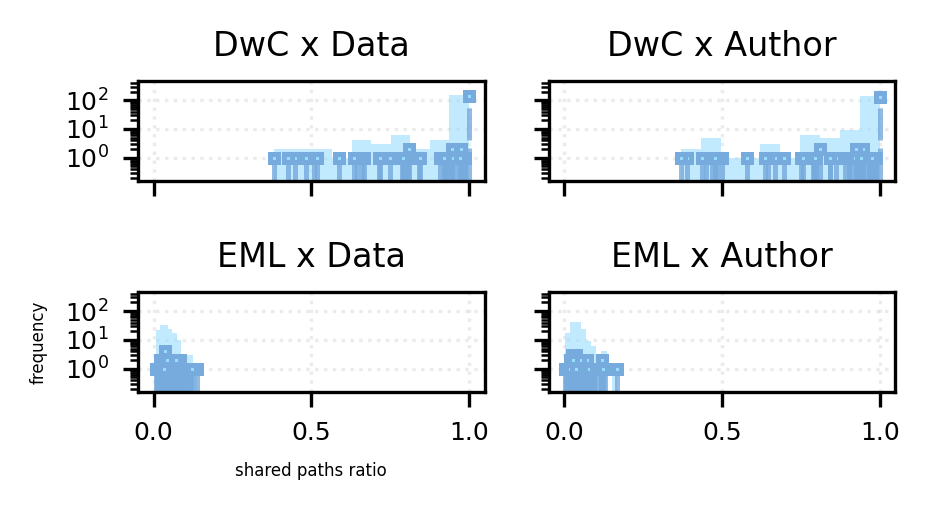

In [402]:
fig, axs = plt.subplots(2, 2, dpi=300, figsize=(3.2,1.8), sharex=True, sharey=True)

for i, (ax, (g, rs)) in enumerate(zip(itlx.chain.from_iterable(axs), result_groups.items())):
    ok_rs = with_ok_parsed_trees(rs)
    ax.set_title(g.replace("-", " "))
    ax.hist(ok_rs["xml_tree.ground_truth.overlap_pattern_score"], color=tcls.light[4], log=True, alpha=0.6)
    ax.vlines(
        ymin=0, 
        ymax=ok_rs["xml_tree.ground_truth.overlap_pattern_score"].value_counts().values, 
        x=ok_rs["xml_tree.ground_truth.overlap_pattern_score"].value_counts().index, 
        ls="-.",
        color=tcls.light[0],
        linewidth=1.2,
        alpha=0.8
    )
    ax.plot(
        ok_rs["xml_tree.ground_truth.overlap_pattern_score"].value_counts(), 
        marker="s", 
        color="#ffffff00", 
        markerfacecolor=tcls.light[4], 
        markeredgecolor=tcls.light[0], 
        markeredgewidth=1.2,
        markersize=2,
        label=""
    )
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ymargin(0.2)
    ax.set_xmargin(0.4)
    ax.set_ylabel("frequency", fontsize=4) if (i == 2) else ...
    ax.set_xlabel("shared paths ratio", fontsize=4) if (i == 2) else ...

# fig.suptitle("Path Overlap Ratio of Generated and Ground Truth XML", fontsize=8)

plt.tight_layout()
plt.savefig("generated-pareseable-xml-gt-gen-shared-path-score-hist.pdf")
plt.savefig("generated-pareseable-xml-gt-gen-shared-path-score-hist.png")
plt.show()

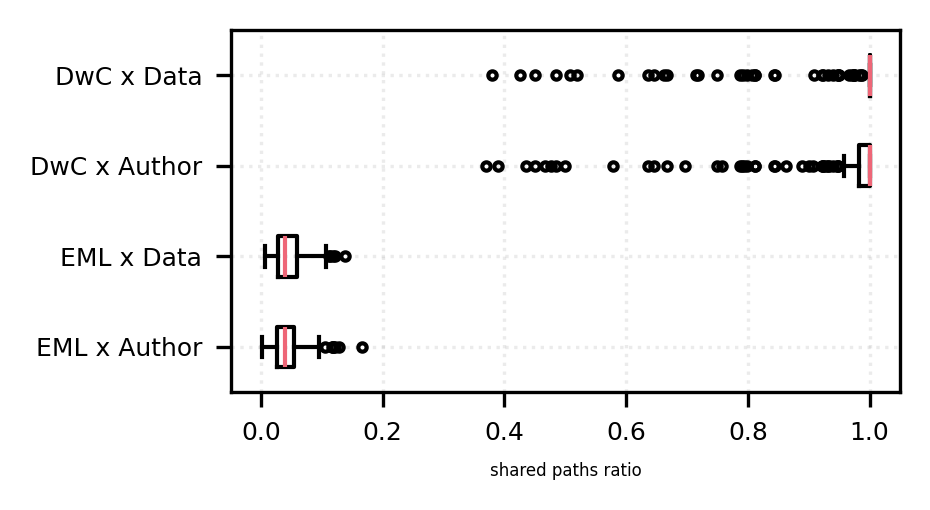

In [403]:
fig, ax = plt.subplots(1, 1, dpi=300, figsize=(3.2,1.8))

# ax.set_title("Shared Path Score")
ax.boxplot(
    [
       with_ok_parsed_trees(rs)["xml_tree.ground_truth.overlap_pattern_score"]
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    tick_labels=[
       g.replace("-", " ")
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    vert=False,
    flierprops=dict(markersize=2),
)
ax.set_xlabel("shared paths ratio", fontsize=4)
ax.grid(alpha=0.25, ls=":")
ax.set_axisbelow(True)


plt.tight_layout()
plt.savefig("generated-pareseable-xml-gt-gen-shared-path-score-boxplot.pdf")
plt.savefig("generated-pareseable-xml-gt-gen-shared-path-score-boxplot.png")
plt.show()

In [404]:
intersection_path_groups = {}

for g, rs in result_groups.items():
    ok_rs = with_ok_parsed_trees(rs)
    intersection_path_groups[g] = pd.Series(
        itlx.chain.from_iterable(ok_rs["xml_tree.ground_truth.path_intersection"].apply(list).tolist())
    )

    print(g)
    print(intersection_path_groups[g].describe())

DwC-x-Data
count                                                  7575
unique                                                  321
top       {http://rs.tdwg.org/dwc/text/}core/{http://rs....
freq                                                    174
dtype: object
DwC-x-Author
count                                                  7540
unique                                                  319
top       {http://rs.tdwg.org/dwc/text/}core/{http://rs....
freq                                                    174
dtype: object
EML-x-Data
count              1011
unique               45
top       dataset/title
freq                150
dtype: object
EML-x-Author
count               976
unique               28
top       dataset/title
freq                148
dtype: object


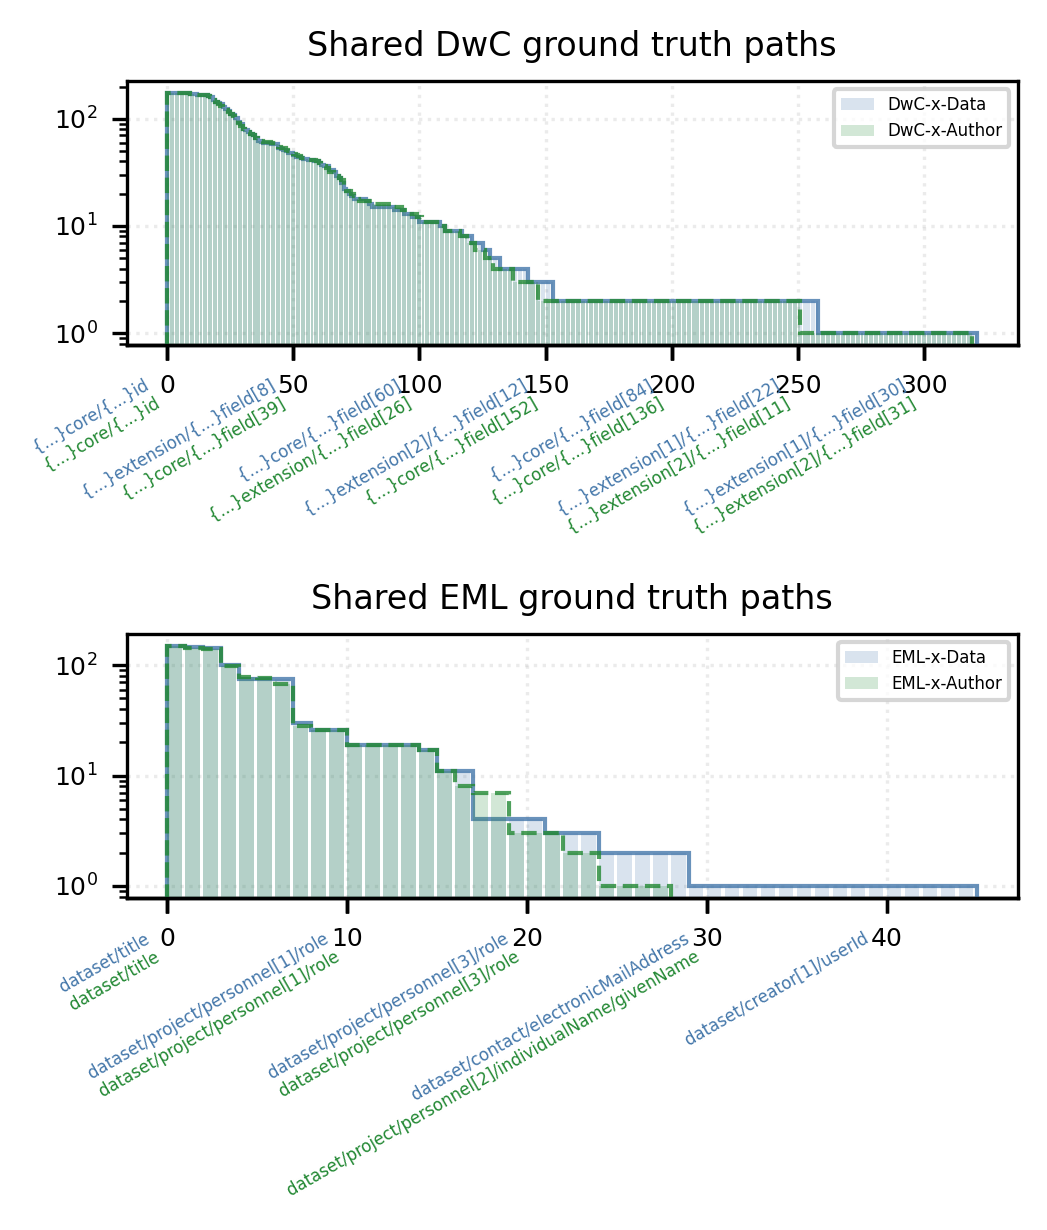

In [405]:
fig, axs = plt.subplots(2, 1, dpi=300, figsize=(3.6,4.2), sharex=False)

for i, (ax, (gs)) in enumerate(zip(axs, [["DwC-x-Data", "DwC-x-Author"], ["EML-x-Data", "EML-x-Author"]])):
    ax.set_title(f"Shared {gs[0][:3]} ground truth paths")
    for (j, g), c, ls in zip(enumerate(gs), [tcls.bright[0], tcls.bright[2]], ["-", "--"]):
        ok_rs = with_ok_parsed_trees(result_groups[g])
        vcounts = pd.Series(
            itlx.chain.from_iterable(ok_rs["xml_tree.ground_truth.path_intersection"].apply(list).tolist())
        ).value_counts()
        _xs = list(enumerate(vcounts.index.tolist()))
        xs = [_i for _i, v in _xs]
        xs_labels = [("\n" if j else "") + re.sub(r'\{[^\}]+\}', '{...}', v) + (" " if j else " \n") for i, v in _xs]
        ys = vcounts.values
        ax.bar(xs, ys, color=c, alpha=0.2, align="edge", log=True, label=g)
        # ax.stairs(ys, color=c, alpha=0.8, ls=ls, label=g[6:])
        ax.stairs(ys, color=c, alpha=0.8, ls=ls)
        # ax.plot(xs, ys, color="#ffffff00", edgecolor="black", ls=ls)
        # ax.legend(fontsize=4)
        tick_seeds = [int(t) for t in ax.get_xticks().tolist()]
        tick_labels = [l for s in (tick_seeds + [max(xs)]) if (s < len(xs_labels)) and (l:=xs_labels[s])]
        secx = ax.secondary_xaxis(location=0)
        tick_target = ax if j == 0 else secx
        tick_target.set_xticks(tick_seeds[:len(tick_labels)])
        tick_target.set_xticklabels(
            tick_labels, 
            # minor=True, 
            rotation=30, 
            ha="right",
            fontsize=4,
            # va="bottom" if j == 0 else "top",
            color=c
        )
        # ax.set_xlabel("frequency", fontsize=4)
    ax.legend(fontsize=4)
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("generated-pareseable-xml-shared-gt-paths.pdf")
plt.savefig("generated-pareseable-xml-shared-gt-paths.png")
plt.show()

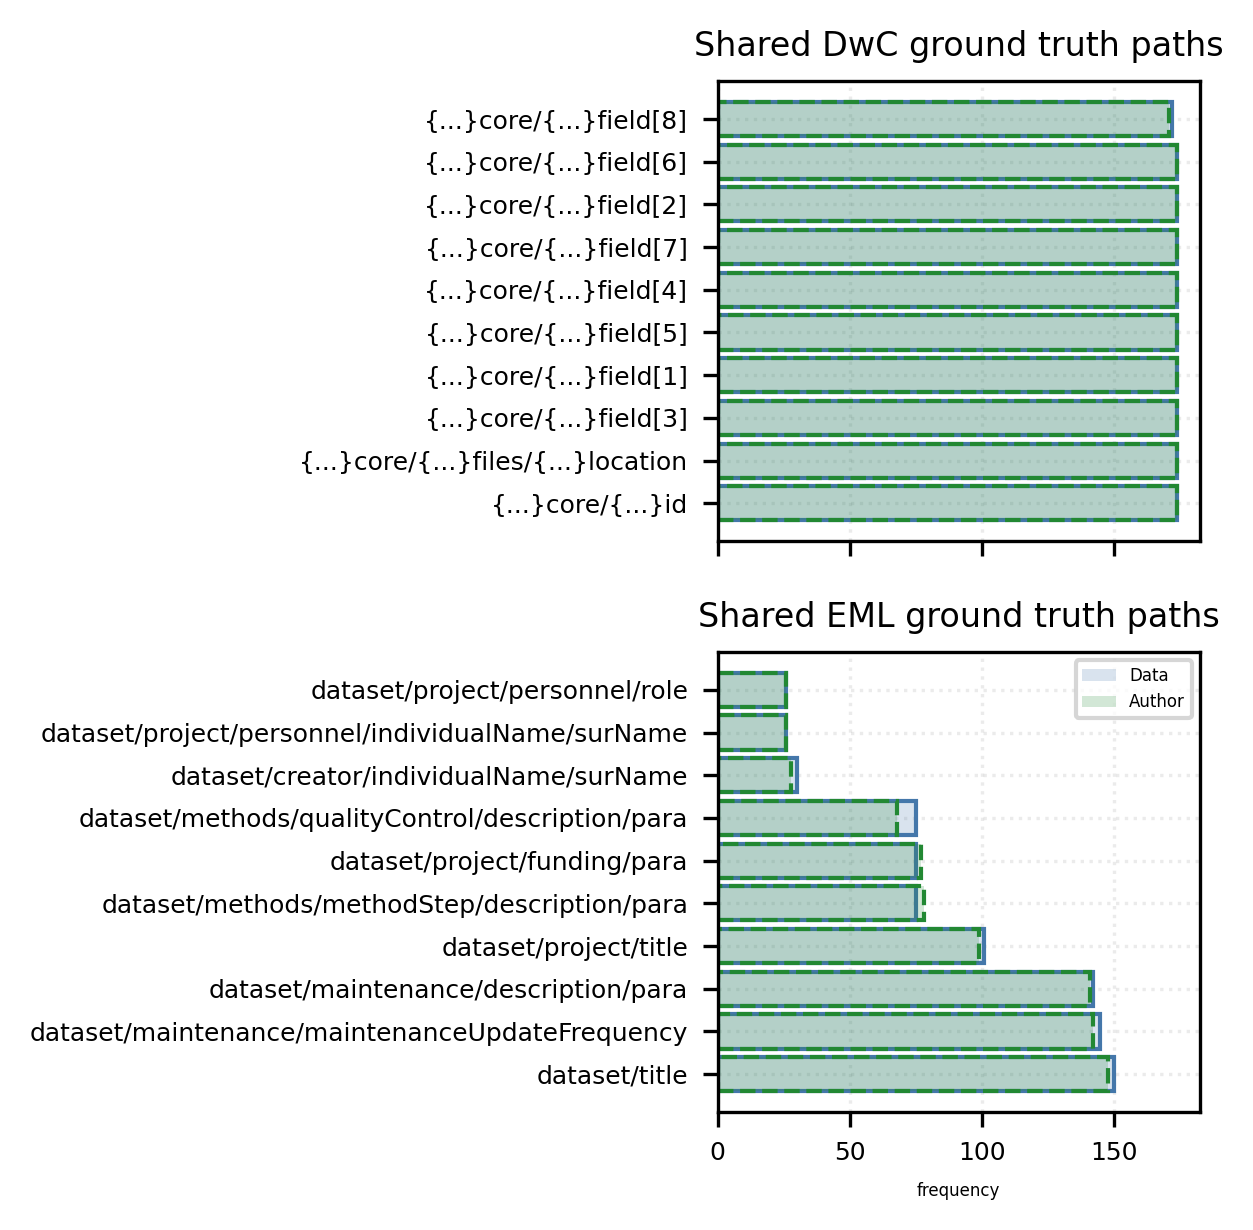

In [406]:
fig, axs = plt.subplots(2, 1, dpi=300, figsize=(4.2,4.2), sharex=True)

head_count = 10
for i, (ax, (gs)) in enumerate(zip(axs, [["DwC-x-Data", "DwC-x-Author"], ["EML-x-Data", "EML-x-Author"]])):
    ax.set_title(f"Shared {gs[0][:3]} ground truth paths")
    for g, c, ls in zip(gs, [tcls.bright[0], tcls.bright[2]], ["-", "--"]):
        ok_rs = with_ok_parsed_trees(result_groups[g])
        vcounts = pd.Series(
            itlx.chain.from_iterable(ok_rs["xml_tree.ground_truth.path_intersection"].apply(list).tolist())
        ).value_counts().head(head_count)
        xs = list(map(lambda i: re.sub(r'\{[^\}]+\}', '{...}', i), vcounts.index.tolist()))
        ys = vcounts.values
        ax.barh(xs, ys, label=g[6:], color=c, alpha=0.2)
        ax.barh(xs, ys, color="#ffffff00", edgecolor=c, ls=ls)
    if i == 1:
        ax.legend(fontsize=4)
        ax.set_xlabel("frequency", fontsize=4)
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("generated-pareseable-xml-shared-gt-paths.pdf")
plt.savefig("generated-pareseable-xml-shared-gt-paths.png")
plt.show()

In [407]:
insp_rs = with_ok_parsed_trees(result_groups["DwC-x-Data"])
lowest_insp_rs = list(insp_rs[insp_rs["xml_tree.ground_truth.overlap_pattern_score"] == insp_rs["xml_tree.ground_truth.overlap_pattern_score"].min()].iterrows())

In [408]:
lowest_insp_rs[0][1]["xml_tree.ground_truth.path_intersection"]

{'{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[12]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[14]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[11]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[15]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[9]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3]', '{http://rs.tdwg.

In [409]:
lowest_insp_rs[0][1]["xml_tree.ground_truth.path_union"]

{'{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[12]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[22]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[14]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[21]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[15]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[17]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[18]', '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[37]', '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[35]', '{http://rs.tdwg.org/dwc/text/}core

> ~**Bide-Based Computations**~ -- Too confusing and impractical

In [410]:
# import prefixspan as pfxsc

In [411]:
# %%time
# min_support = 2
# for g, rs in result_groups.items():
#     result_groups[g]["prefix_span_db"] = with_ok_parsed_trees(rs)[["xml_tree.unique_paths", "ground_truth_xml_tree.unique_paths"]].apply(
#         lambda r: r["xml_tree.unique_paths"] + r["ground_truth_xml_tree.unique_paths"],
#         axis=1
#     )
#     result_groups[g]["xml_tree.ground_truth.bide.shared_closed_embedded_path"] = with_ok_parsed_trees(result_groups[g])["prefix_span_db"].apply(
#         lambda db: pfxsc.PrefixSpan(db).frequent(min_support, closed=True)
#     )

### [x] Node Jaccard Index

In [436]:
for g, rs in result_groups.items():
    result_groups[g]["xml_tree.ground_truth.node_intersection"] = with_ok_parsed_trees(rs).apply(
        lambda d: set.intersection(
            set(d["xml_tree.characteristics"]["value"]["all_nodes"]), 
            set(d["ground_truth_xml_tree.characteristics"]["value"]["all_nodes"]), 
        ), 
        axis=1
    )
    result_groups[g]["xml_tree.ground_truth.node_union"] = with_ok_parsed_trees(rs).apply(
        lambda d: set.union(
            set(d["xml_tree.characteristics"]["value"]["all_nodes"]), 
            set(d["ground_truth_xml_tree.characteristics"]["value"]["all_nodes"]), 
        ), 
        axis=1
    )
    result_groups[g]["xml_tree.ground_truth.node_jaccard_index"] = with_ok_parsed_trees(result_groups[g])["xml_tree.ground_truth.node_intersection"].apply(len).div(
        with_ok_parsed_trees(result_groups[g])["xml_tree.ground_truth.node_union"].apply(len)
    )

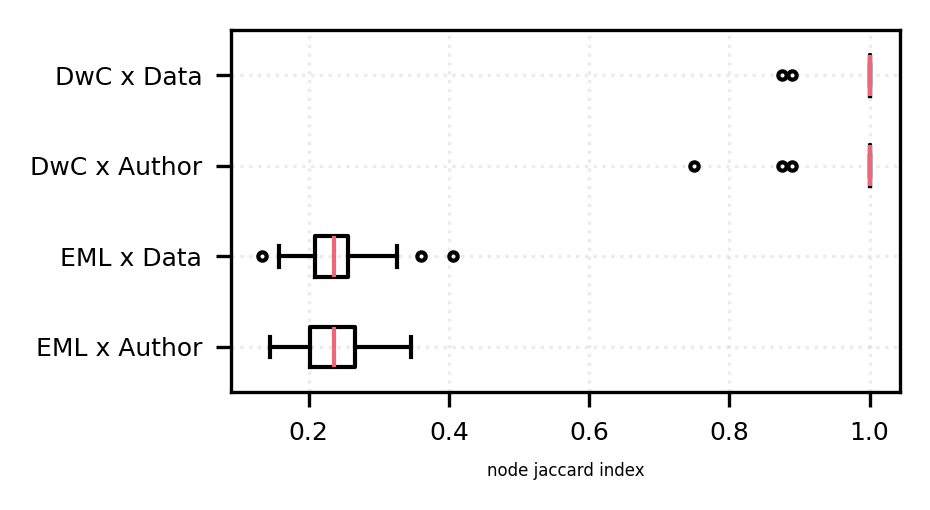

In [441]:
fig, ax = plt.subplots(1, 1, dpi=300, figsize=(3.2,1.8))

# ax.set_title("Shared Path Score")
ax.boxplot(
    [
       with_ok_parsed_trees(rs)["xml_tree.ground_truth.node_jaccard_index"]
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    tick_labels=[
       g.replace("-", " ")
       for (g, rs) in reversed(list(result_groups.items())) 
    ],
    vert=False,
    flierprops=dict(markersize=2),
)
ax.set_xlabel("node jaccard index", fontsize=4)
ax.grid(alpha=0.25, ls=":")
ax.set_axisbelow(True)


plt.tight_layout()
plt.savefig("generated-pareseable-xml-gt-gen-shared-node-score-boxplot.pdf")
plt.savefig("generated-pareseable-xml-gt-gen-shared-node-score-boxplot.png")
plt.show()

## [x] Semantic Metadata Path Value Alignment

- value comparison along the embedded paths

In [ ]:
class ElementInfo(TypedDict):
    tag: str
    attributes: dict
    text: str | None

def fetch_element_info(query:str, tree):
    element = tree.find(query)
    return {
        "tag": element.tag,
        "attributes": element.attrib,
        "text": element.text,
    }

In [ ]:
for g,rs in result_groups.items():
    result_groups[g]["xml_tree.ground_truth.path_intersection.gen_elements"] = with_ok_parsed_trees(rs)[
        ["xml_tree.ground_truth.path_intersection", "xml_tree"]
    ].apply(
        lambda r: {
            q: fetch_element_info(q, r["xml_tree"]["value"])
            for q in r["xml_tree.ground_truth.path_intersection"]
        },  
        axis = 1
    )
    result_groups[g]["xml_tree.ground_truth.path_intersection.ground_truth_elements"] = with_ok_parsed_trees(rs)[
        ["xml_tree.ground_truth.path_intersection", "ground_truth_xml_tree"]
    ].apply(
        lambda r: {
            q: fetch_element_info(q, r["ground_truth_xml_tree"]["value"])
            for q in r["xml_tree.ground_truth.path_intersection"]
        },  
        axis = 1
    )   

In [ ]:
result_groups[g]["xml_tree.ground_truth.path_intersection.gen_elements"][4]

In [ ]:
result_groups[g]["xml_tree.ground_truth.path_intersection.ground_truth_elements"][4]

In [ ]:
def fmt_compare_attributes(info: ElementInfo) -> str:
    return "\n".join([f"attribute key: {k} ;; attribute value: {v}" for k,v in sorted(info["attributes"].items())])

def fmt_compare_texts(info: ElementInfo) -> str:
    return str(info["text"])

In [ ]:
from typing import Callable

def _compare_fmt_values(method, fmt, val1, val2):
    return method(fmt(val1), fmt(val2))

def _compute_info_sim(method, fmt, r1, r2):
    return {k: _compare_fmt_values(method, fmt, v, r2[k]) for k,v in r1.items()}

def compare_attributes(method: Callable[[str, str], float], r1: dict[str, ElementInfo], r2: dict[str, ElementInfo]) -> dict[str, Any]:
    return _compute_info_sim(method, fmt_compare_attributes, r1, r2)

def compare_texts(method: Callable[[str, str], float], r1: dict[str, ElementInfo], r2: dict[str, ElementInfo]) -> dict[str, Any]:
     return _compute_info_sim(method, fmt_compare_texts, r1, r2)

In [ ]:
with_ok_parsed_trees(result_groups[g])[
    ["xml_tree.ground_truth.path_intersection.gen_elements", "xml_tree.ground_truth.path_intersection.ground_truth_elements"]
].apply(
    lambda r: compare_attributes(
        lambda x,y: int(x == y), 
        r["xml_tree.ground_truth.path_intersection.gen_elements"], 
        r["xml_tree.ground_truth.path_intersection.ground_truth_elements"]
    ),
    axis=1,
).tolist()[0]

In [ ]:
with_ok_parsed_trees(result_groups[g])[
    ["xml_tree.ground_truth.path_intersection.gen_elements", "xml_tree.ground_truth.path_intersection.ground_truth_elements"]
].apply(
    lambda r: compare_texts(
        lambda x,y: int(x == y), 
        r["xml_tree.ground_truth.path_intersection.gen_elements"], 
        r["xml_tree.ground_truth.path_intersection.ground_truth_elements"]
    ),
    axis=1,
).tolist()[0]

In [ ]:
import warnings
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    
    model = SentenceTransformer('all-MiniLM-L6-v2')
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

def compute_cos_similarity(v1, v2):
    if not v1 or not v2:
        return np.nan
        
    emb1 = model.encode(v1).reshape(1,-1)
    emb2 = model.encode(v2).reshape(1,-1)

    sim_matrix = cosine_similarity(emb1, emb2)
    score = (np.mean(np.max(sim_matrix, axis=1)) + np.mean(np.max(sim_matrix, axis=0))) / 2
    return score

In [ ]:
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

r_scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
smoothing = SmoothingFunction().method1

SIM_SCORE_KEYS = ["cos_sim", "bleu", "rouge_l"]

class SemanticSimilarityScores(TypedDict):
    cos_sim: float
    bleu: float
    rouge_l: float
    v1_len: int
    v2_len: int

def get_semantic_similarity_metrics(v1: str, v2: str, min_words=4) -> SemanticSimilarityScores:
    v1_input = v1.strip()
    v2_input = v2.strip()
    
    v1_wc = len(v1.split())
    v2_wc = len(v2.split())

    if COS_SIMILARITY_READY:
        cos_sim = compute_cos_similarity(v1_input, v2_input) if v1_input and v2_input else 0.0
    else:
        cos_sim = np.nan

    if v1_wc < min_words or v2_wc < min_words:
        bleu = np.nan
        rouge_l = np.nan
    else:
        bleu = sentence_bleu([v1_input.split()], v2_input.split(), smoothing_function=smoothing)
        rouge_l = r_scorer.score(v1_input, v2_input)['rougeL'].fmeasure

    return {
        "cos_sim": cos_sim,
        "bleu": bleu,
        "rouge_l": rouge_l,
        "v1_len": v1_wc,
        "v2_len": v2_wc,
        "v1_input": v1_input,
        "v2_input": v2_input,
    }

In [ ]:
for g,rs in result_groups.items():
    result_groups[g]["xml_tree.ground_truth.path_intersection.sim_metrics.text"] = with_ok_parsed_trees(rs)[
        ["xml_tree.ground_truth.path_intersection.gen_elements", "xml_tree.ground_truth.path_intersection.ground_truth_elements"]
    ].apply(
        lambda r: compare_texts(
            get_semantic_similarity_metrics, 
            r["xml_tree.ground_truth.path_intersection.gen_elements"], 
            r["xml_tree.ground_truth.path_intersection.ground_truth_elements"]
        ),
        axis=1,
    )
    result_groups[g]["xml_tree.ground_truth.path_intersection.sim_metrics.attributes"] = with_ok_parsed_trees(rs)[
        ["xml_tree.ground_truth.path_intersection.gen_elements", "xml_tree.ground_truth.path_intersection.ground_truth_elements"]
    ].apply(
        lambda r: compare_attributes(
            get_semantic_similarity_metrics, 
            r["xml_tree.ground_truth.path_intersection.gen_elements"], 
            r["xml_tree.ground_truth.path_intersection.ground_truth_elements"]
        ),
        axis=1,
    )

In [ ]:
for g,rs in result_groups.items():
    for m in SIM_SCORE_KEYS:
        result_groups[g][f"xml_tree.ground_truth.path_intersection.sim_metrics.text.{m}"] =  with_ok_parsed_trees(rs)[
            "xml_tree.ground_truth.path_intersection.sim_metrics.text"
        ].apply(lambda r: {k: v[m] for k, v in r.items()})

        
        result_groups[g][f"xml_tree.ground_truth.path_intersection.sim_metrics.attributes.{m}"] =  with_ok_parsed_trees(rs)[
            "xml_tree.ground_truth.path_intersection.sim_metrics.attributes"
        ].apply(lambda r: {k: v[m] for k, v in r.items()})

In [ ]:
for g,rs in result_groups.items():
    print(with_ok_parsed_trees(rs)[[
        "short_scenario_x_case_tag",
        "xml_tree.ground_truth.path_intersection.gen_elements", 
        "xml_tree.ground_truth.path_intersection.ground_truth_elements", 
        "xml_tree.ground_truth.path_intersection.sim_metrics.attributes"
    ]].head())

In [ ]:
result_attribute_sem_metric_groups = {}

for g,rs in result_groups.items():
    result_attribute_sem_metric_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(with_ok_parsed_trees(rs)[
            "xml_tree.ground_truth.path_intersection.sim_metrics.attributes"
        ].apply(
            lambda ms: [{"path": k, **vs} for k,vs in ms.items()]
        ).tolist())
    )

In [ ]:
result_text_sem_metric_groups = {}

for g,rs in result_groups.items():
    result_text_sem_metric_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(with_ok_parsed_trees(rs)[
            f"xml_tree.ground_truth.path_intersection.sim_metrics.text"
        ].apply(
            lambda ms: [{"path": k, **vs} for k,vs in ms.items()]
        ).tolist())
    )

In [ ]:
for i, (gs) in enumerate([["DwC-x-Data", "DwC-x-Author"], ["EML-x-Data", "EML-x-Author"]]):
    for g, c, ls in zip(gs, [tcls.bright[0], tcls.bright[2]], ["-", "--"]):
        ok_ms = result_attribute_sem_metric_groups[g]
        for m in SIM_SCORE_KEYS:
            print(m)
            print(ok_ms.groupby(by="path")[m].describe())

In [ ]:
for g in ["DwC-x-Data", "DwC-x-Author"]:
    ok_ms = result_attribute_sem_metric_groups[g]
    gms = ok_ms.groupby(by="path")
    print(gms[m].describe().to_latex())

In [ ]:
for g in ["DwC-x-Data", "DwC-x-Author"]:
    ok_ms = result_attribute_sem_metric_groups[g]
    gms = ok_ms.groupby(by="path")
    print(gms[m].describe())

In [ ]:
import pprint
pprint.pprint(
    list(map(
        lambda x: (x[0], dict(x[1])), 
        result_attribute_sem_metric_groups["DwC-x-Data"][["path", "v1_input","v2_input", "bleu"]].head().iterrows()
    ))
)

In [ ]:
fig, axs = plt.subplots(2, 2, dpi=300, figsize=(2.4, 2.4), sharey=True, sharex=True)

head_count = 10
fig.suptitle("Pooled Attribute Similarity Scores", fontsize=6)
for i, (ax, (g, ok_ms)) in enumerate(zip(itlx.chain.from_iterable(axs), result_attribute_sem_metric_groups.items())):
    ax.boxplot(
        [ok_ms[m].dropna() for m in SIM_SCORE_KEYS],
        tick_labels = SIM_SCORE_KEYS,
        vert=False,
        flierprops=dict(markersize=2),
    )
    if i > 1:
        ax.set_xlabel("semantic similarity score", fontsize=4)
    ax.set_title(g.replace("-", " "))
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig("generated-pareseable-xml-shared-gt-paths-semantic-sim-attributes.pdf")
plt.savefig("generated-pareseable-xml-shared-gt-paths-semantic-sim-attributes.png")
plt.show()

In [ ]:
fig, axs = plt.subplots(2, 2, dpi=300, figsize=(2.4, 2.4), sharey=True, sharex=True)

head_count = 10
fig.suptitle("Pooled Text Similarity Scores", fontsize=6)
for i, (ax, (g, ok_ms)) in enumerate(zip(itlx.chain.from_iterable(axs), result_text_sem_metric_groups.items())):
    ax.boxplot(
        [ok_ms[m].dropna() for m in SIM_SCORE_KEYS],
        tick_labels = SIM_SCORE_KEYS,
        vert=False,
        flierprops=dict(markersize=2),
    )
    if i > 1:
        ax.set_xlabel("semantic similarity score", fontsize=4)
    ax.set_title(g.replace("-", " "))
    ax.grid(alpha=0.25, ls=":")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("generated-pareseable-xml-shared-gt-paths-semantic-sim-text.pdf")
plt.savefig("generated-pareseable-xml-shared-gt-paths-semantic-sim-text.png")
plt.show()

## [ ] Semantic Metadata Tree Alignment

- cosine similarity over the whole tree

## [ ] Composite Metadata Alignment Score

- composite metric from the previous values